# Thực nghiệm 4: Thử tham số class_weight cho SVM

Thực nghiệm SVM RBF trên tập A gồm **3.539 mẫu và 36 đặc trưng**, so sánh `class_weight="balanced"` với `class_weight=None` để đánh giá tác động của việc điều chỉnh trọng số lớp. Giữ nguyên các tham số còn lại, cùng tiền xử lý và **Stratified 5-fold CV, random_state=42**. Kết quả được lưu dưới dạng Excel, CSV và biểu đồ trong thư mục thực nghiệm.


## 1. Cấu hình và tham số

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold

cwd = Path.cwd().resolve()
project_dir = next(
    (p for p in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
     if (p / "feature_b" / "common.py").is_file()
     and (p / "data" / "processed" / "development.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy ML01_Student_Dropout. Hãy mở repo trong VS Code.")

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

output_dir = project_dir / "experiments" / "2026-11-14_ThuThamSo_SVM_Triet"
data_path = project_dir / "data" / "processed" / "development.csv"
N_FOLDS = 5
SEED = 42

configs = {
    "SVM goc (balanced)": {"kernel": "rbf", "C": 10, "gamma": 0.01, "class_weight": "balanced"},
    "SVM thu (None)": {"kernel": "rbf", "C": 10, "gamma": 0.01, "class_weight": None},
}
print("Project:", project_dir)
print("Output:", output_dir)
print("sklearn:", sklearn.__version__)
display(pd.DataFrame([{"Cau hinh": name, **params} for name, params in configs.items()]))

Project: D:\sgu-MAYHOC\ML01_Student_Dropout
Output: D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_SVM_Triet
sklearn: 1.7.2


,Cau hinh,kernel,C,gamma,class_weight
0,SVM goc (balanced),rbf,10,0.01,balanced
1,SVM thu (None),rbf,10,0.01,None


## 2. Huấn luyện và đánh giá hai cấu hình SVM

Mỗi cấu hình được đánh giá trên **cùng 5 fold**. Tiền xử lý nằm trong pipeline và được fit riêng trên dữ liệu huấn luyện của từng fold.

In [2]:
X_a, _, y = load_development(data_path)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []
for name, params in configs.items():
    print(f"Đang đánh giá: {name}")
    model = SVC(**params)
    summary, fold_scores = evaluate(name, model, True, "A", X_a, y, folds)
    summary_rows.append({**summary, "class_weight": str(params["class_weight"])})
    fold_tables.append(fold_scores)

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True)
old_score = results.loc[results["class_weight"].eq("balanced"), "cv_macro_f1"].iloc[0]
new_score = results.loc[results["class_weight"].eq("None"), "cv_macro_f1"].iloc[0]
delta = new_score - old_score

print(f"balanced: {old_score:.6f}")
print(f"None    : {new_score:.6f}")
print(f"Chênh lệch (None - balanced): {delta:+.6f}")
display(results.round(6))
display(fold_results.round(6))

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang đánh giá: SVM goc (balanced)
Đang đánh giá: SVM thu (None)
balanced: 0.715364
None    : 0.705381
Chênh lệch (None - balanced): -0.009982


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate,class_weight
0,SVM goc (balanced),A,36,0.715364,0.736148,0.595276,0.832484,balanced
1,SVM thu (None),A,36,0.705381,0.760774,0.407874,0.920204,None


,model,data,fold,macro_f1
0,SVM goc (balanced),A,1,0.726732
1,SVM goc (balanced),A,2,0.711875
2,SVM goc (balanced),A,3,0.727087
3,SVM goc (balanced),A,4,0.700751
4,SVM goc (balanced),A,5,0.710372
5,SVM thu (None),A,1,0.734471
6,SVM thu (None),A,2,0.681023
7,SVM thu (None),A,3,0.705257
8,SVM thu (None),A,4,0.688920
9,SVM thu (None),A,5,0.717236


## 3. Tổng hợp và xuất kết quả thực nghiệm

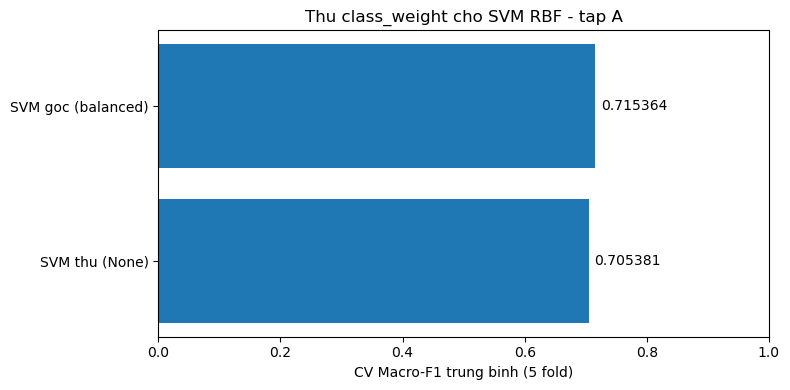


Da xuat cac file:
 - D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_SVM_Triet\ket_qua.xlsx
 - D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_SVM_Triet\ket_qua_tong_hop.csv
 - D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_SVM_Triet\diem_tung_fold.csv
 - D:\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_SVM_Triet\so_sanh_macro_f1.png


In [3]:
output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "ket_qua.xlsx"
summary_csv = output_dir / "ket_qua_tong_hop.csv"
fold_csv = output_dir / "diem_tung_fold.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Nguoi thuc hien": "Tran Minh Triet",
    "Du lieu": "data/processed/development.csv",
    "Tap dac trung": "A",
    "So mau": len(y),
    "So dac trung": X_a.shape[1],
    "So fold": N_FOLDS,
    "CV": "StratifiedKFold(shuffle=True, random_state=42)",
    "Tien xu ly": "OneHot categorical; StandardScaler numeric; binary passthrough",
    "Chi so chinh": "CV Macro-F1 trung binh",
    "Tham so thay doi": "class_weight: balanced -> None",
    "sklearn_version": sklearn.__version__,
}])

results.to_csv(summary_csv, index=False, encoding="utf-8-sig")
fold_results.to_csv(fold_csv, index=False, encoding="utf-8-sig")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin thuc nghiem", index=False)
    pd.DataFrame([{"Cau hinh": name, **params} for name, params in configs.items()]).to_excel(
        writer, sheet_name="Cau hinh mo hinh", index=False
    )

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(results["model"], results["cv_macro_f1"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung binh (5 fold)")
ax.set_title("Thu class_weight cho SVM RBF - tap A")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180)
plt.show()
plt.close(fig)

print("\nDa xuat cac file:")
for path in [excel_path, summary_csv, fold_csv, image_path]:
    print(" -", path)

## 4. Nhận xét

Sau khi chạy, điền điểm thực tế từ bảng kết quả:

- **SVM gốc (`class_weight="balanced"`):** CV Macro-F1 = 0.715364
- **SVM thử (`class_weight=None`):** CV Macro-F1 = 0.705381
- **Chênh lệch:** -0.009982 (None trừ balanced).

Nếu điểm của cấu hình `None` cao hơn, việc bỏ trọng số cân bằng có lợi cho Macro-F1 trong lần thử này; nếu thấp hơn, giữ `balanced`. Đối chiếu thêm Recall OOF của **Dropout, Enrolled, Graduate** để tránh kết luận chỉ dựa trên một chỉ số. Đây là đánh giá CV trên development, **chưa phải đánh giá tập test độc lập**.